# 0. Environment Setup

In [1]:
# Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, precision_recall_curve, auc, precision_score, recall_score
import xgboost as xgb
from imblearn.over_sampling import SMOTE
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import re
import os

import sys
sys.path.insert(0, '..')

from src.config import (RAW_DATA_DIR, ROOT_DIR, PROCESSED_DATA_DIR, MODELS_DIR)

# Show all columns 
pd.set_option('display.max_columns', None)

# Bold Text Setup
b_start = '\033[1m'
b_end = '\033[0m'

# Graph visual style
sns.set_theme(style='whitegrid')

print('Environment Ready')

Environment Ready


-----
# 1. Complaint Narrative NLP

In [2]:
# Cleaned Dataset Load
print('Dataframe Loading...')

data = pd.read_csv(fr'{RAW_DATA_DIR}\creditcard_transactions.csv', low_memory=False)

print('Dataframe Correctly Loaded')
print()
display(data.sample(3))

Dataframe Loading...
Dataframe Correctly Loaded



,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
152747,97454.0,-1.144382,0.335843,2.362922,-0.667371,0.543020,0.180223,-0.253161,0.094478,1.505629,-1.252894,-0.189131,-2.232076,2.782834,0.743131,-0.227038,0.646128,-0.093624,0.454869,-0.329070,-0.066144,-0.142961,-0.115524,-0.396236,0.485334,0.241783,0.545198,-0.068691,0.029111,15.95,0
98137,66535.0,-2.405011,0.825020,1.286115,1.508295,-0.840691,1.276616,-0.555796,1.058862,0.836294,0.275197,-0.051207,0.880533,-1.154711,-0.242354,-1.846512,-1.140798,1.019188,-0.352580,1.734675,-0.278900,-0.398440,-0.526124,-0.008787,-0.306926,-0.012639,-0.422900,-0.315500,-0.090171,59.99,0
42295,41034.0,1.298881,-0.649012,0.846275,-0.769185,-1.200153,-0.246700,-0.977766,0.178763,-0.791475,0.748592,1.762996,-0.079494,-0.576982,0.092570,0.551836,1.232460,0.288995,-1.272515,0.337777,-0.001661,0.125469,0.236139,0.132533,0.209947,0.100944,-0.364609,0.031872,0.011858,5.69,0


Variables defined and scaled

=== Non Supervised Isolation Forest (contamination = 0.001)===
Total number of data points: 227845
Number of predicted anomalies (-1): 56
Number of predicted inliers (1): 56906

=== Classification Report (contamination = 0.001)===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.38      0.21      0.27        98

    accuracy                           1.00     56962
   macro avg       0.69      0.61      0.64     56962
weighted avg       1.00      1.00      1.00     56962

=== Confusion Matrix (contamination = 0.001)===


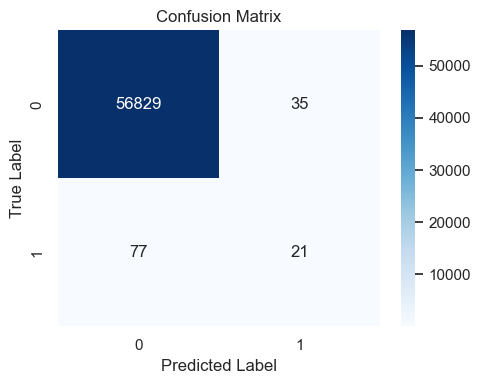

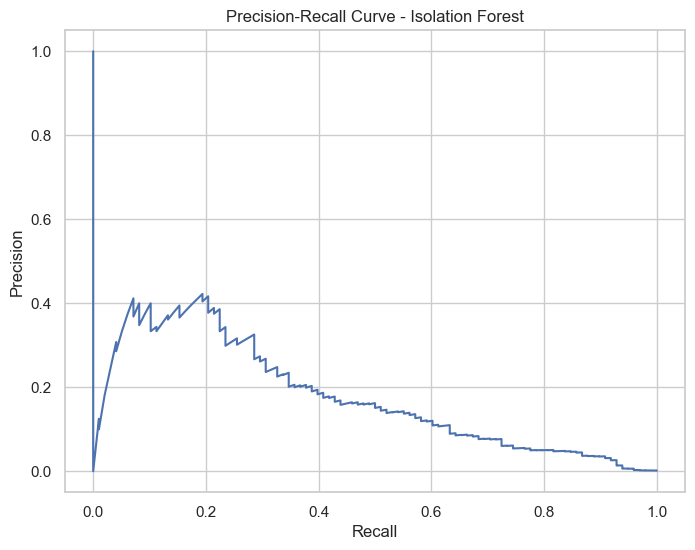

=== Non Supervised Isolation Forest (contamination = 0.002)===
Total number of data points: 227845
Number of predicted anomalies (-1): 111
Number of predicted inliers (1): 56851

=== Classification Report (contamination = 0.002)===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.34      0.39      0.36        98

    accuracy                           1.00     56962
   macro avg       0.67      0.69      0.68     56962
weighted avg       1.00      1.00      1.00     56962

=== Confusion Matrix (contamination = 0.002)===


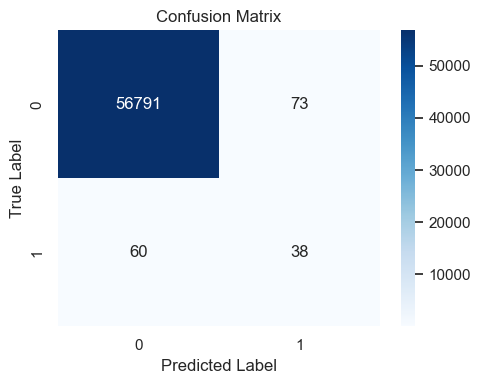

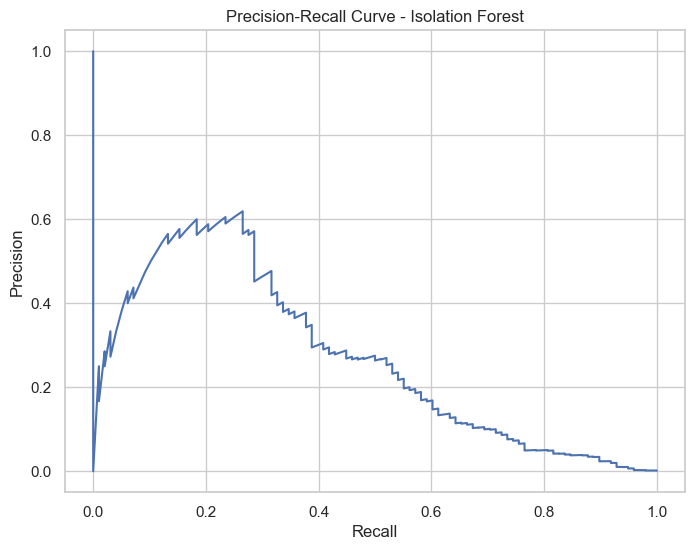

=== Non Supervised Isolation Forest (contamination = 0.005)===
Total number of data points: 227845
Number of predicted anomalies (-1): 269
Number of predicted inliers (1): 56693

=== Classification Report (contamination = 0.005)===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.18      0.49      0.26        98

    accuracy                           1.00     56962
   macro avg       0.59      0.74      0.63     56962
weighted avg       1.00      1.00      1.00     56962

=== Confusion Matrix (contamination = 0.005)===


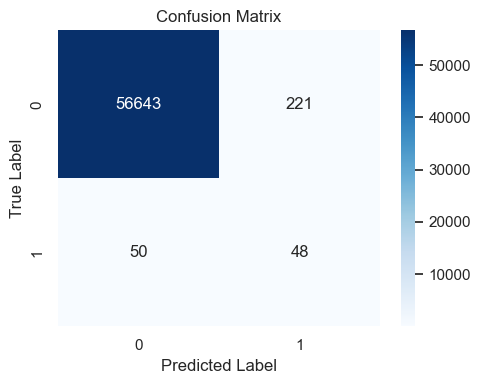

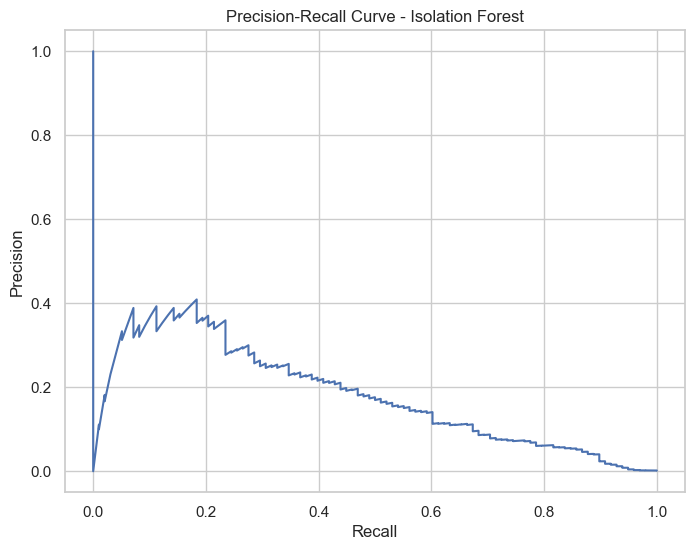

=== Non Supervised Isolation Forest (contamination = 0.01)===
Total number of data points: 227845
Number of predicted anomalies (-1): 531
Number of predicted inliers (1): 56431

=== Classification Report (contamination = 0.01)===
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56864
           1       0.11      0.62      0.19        98

    accuracy                           0.99     56962
   macro avg       0.56      0.81      0.59     56962
weighted avg       1.00      0.99      0.99     56962

=== Confusion Matrix (contamination = 0.01)===


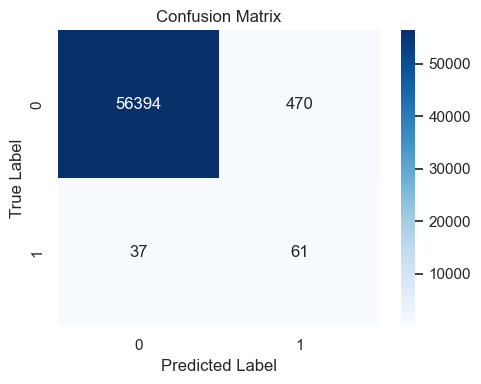

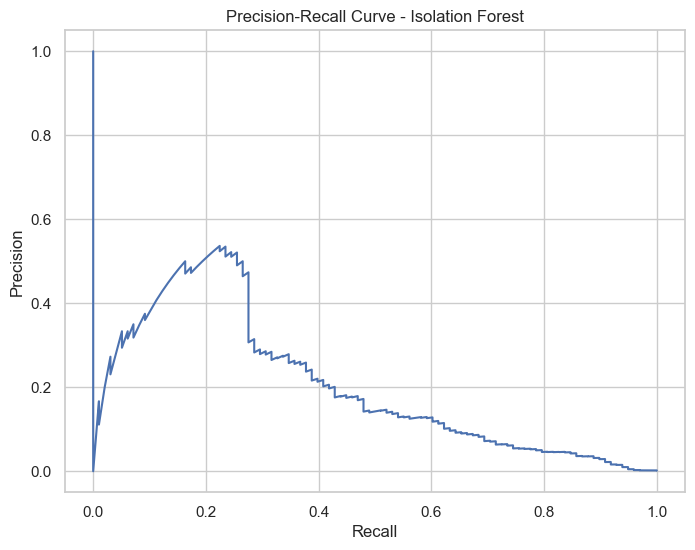

=== Non Supervised Isolation Forest (contamination = 0.02)===
Total number of data points: 227845
Number of predicted anomalies (-1): 1040
Number of predicted inliers (1): 55922

=== Classification Report (contamination = 0.02)===
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.68      0.12        98

    accuracy                           0.98     56962
   macro avg       0.53      0.83      0.55     56962
weighted avg       1.00      0.98      0.99     56962

=== Confusion Matrix (contamination = 0.02)===


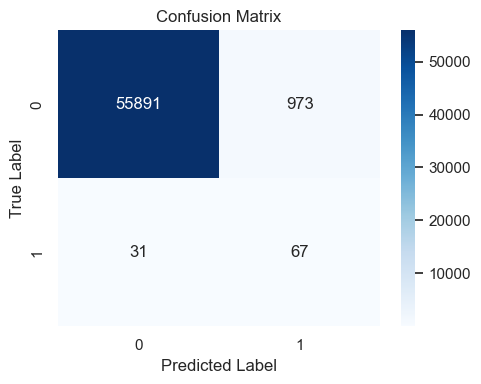

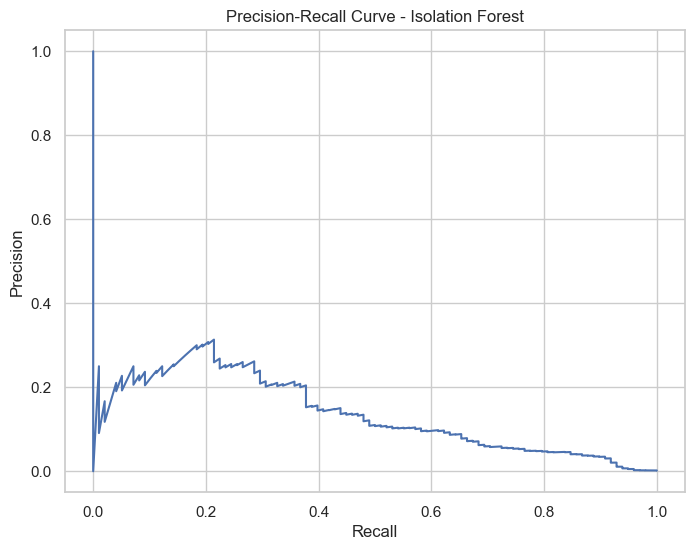

=== Non Supervised Isolation Forest (contamination = 0.05)===
Total number of data points: 227845
Number of predicted anomalies (-1): 2714
Number of predicted inliers (1): 54248

=== Classification Report (contamination = 0.05)===
              precision    recall  f1-score   support

           0       1.00      0.95      0.98     56864
           1       0.03      0.90      0.06        98

    accuracy                           0.95     56962
   macro avg       0.52      0.93      0.52     56962
weighted avg       1.00      0.95      0.97     56962

=== Confusion Matrix (contamination = 0.05)===


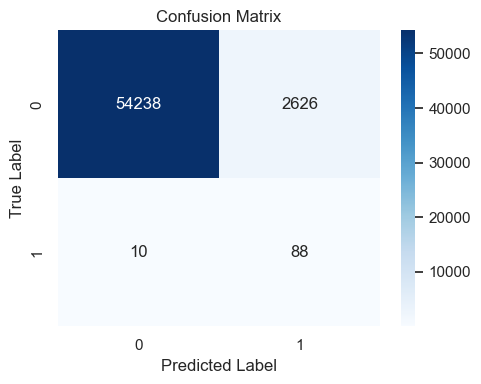

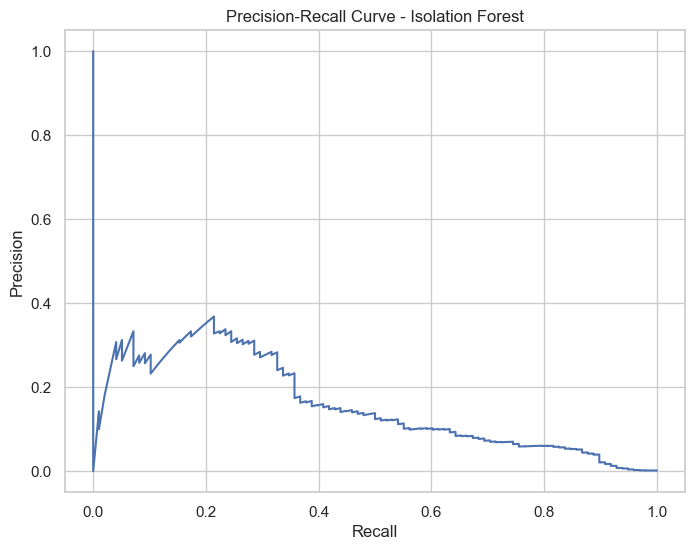

=== Non Supervised Isolation Forest (contamination = 0.1)===
Total number of data points: 227845
Number of predicted anomalies (-1): 5503
Number of predicted inliers (1): 51459

=== Classification Report (contamination = 0.1)===
              precision    recall  f1-score   support

           0       1.00      0.90      0.95     56864
           1       0.02      0.93      0.03        98

    accuracy                           0.90     56962
   macro avg       0.51      0.92      0.49     56962
weighted avg       1.00      0.90      0.95     56962

=== Confusion Matrix (contamination = 0.1)===


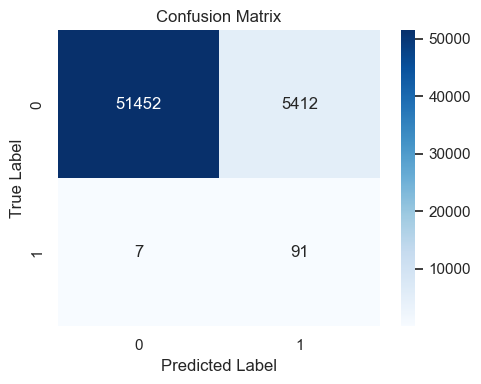

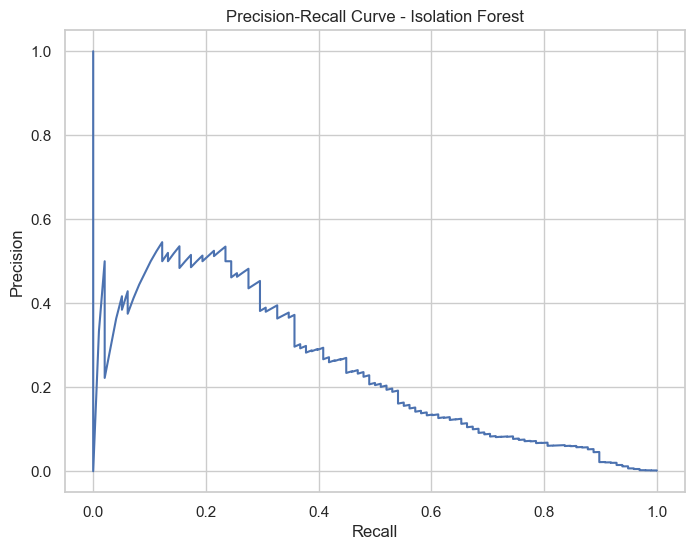

Best fit model selected for contamination=0.002


In [4]:
# Generate confusion matrix
def plot_confusion_matrix(targets, preds):
    cm = confusion_matrix(targets, preds)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()
        
# Scale Amount and Time variables
scaler = StandardScaler()

data['scaled_amount'] = scaler.fit_transform(data[['Amount']])
data['scaled_time'] = scaler.fit_transform(data[['Time']])

# Define X and y values
X = data.drop(columns=['Class', 'Amount', 'Time'])
y = data['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=16, stratify=y)
print('Variables defined and scaled')
print()

contamination_set = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1]
random_state = 101

for c in contamination_set:
    # Initialize and train the Isolation Forest model
    iso_forest = IsolationForest(
        contamination=c, # Check out other configurations for better values
        random_state=random_state, 
        n_jobs=-1
    )
    
    iso_forest.fit(X_train)
    
    # Predict anomalies (-1 for outlier, 1 for inlier)
    predictions = iso_forest.predict(X_test)
    predictions_mapped = np.where(predictions == -1, 1, 0)
    
    scores = -iso_forest.score_samples(X_test)
    precision_if, recall_if, _ = precision_recall_curve(y_test, scores)
    auprc_if = auc(recall_if, precision_if)
    
    # Print the number of predicted anomalies
    print(f'{b_start}=== Non Supervised Isolation Forest (contamination = {c})==={b_end}')
    print(f'Total number of data points: {len(X_train)}')
    print(f'Number of predicted anomalies (-1): {np.sum(predictions == -1)}')
    print(f'Number of predicted inliers (1): {np.sum(predictions == 1)}')
    print()
    print(f'{b_start}=== Classification Report (contamination = {c})==={b_end}')
    print(classification_report(y_test, predictions_mapped))
    print(f'{b_start}=== Confusion Matrix (contamination = {c})==={b_end}')
    plot_confusion_matrix(y_test, predictions_mapped)
    print()

    # Display Precision vs Recall Curve
    plt.figure(figsize=(8,6))
    plt.plot(recall_if, precision_if)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-Recall Curve - Isolation Forest")
    plt.grid(True)
    plt.show()
    
    random_state += 1


# Isolation Forest model selection
best_contamination = 0.002

iso_forest = IsolationForest(
    contamination=best_contamination,
    n_jobs=-1
)

iso_forest.fit(X_train)

# Predict anomalies (-1 for outlier, 1 for inlier)
predictions = iso_forest.predict(X_test)
predictions_mapped = np.where(predictions == -1, 1, 0)

scores = -iso_forest.score_samples(X_test)
precision_if, recall_if, _ = precision_recall_curve(y_test, scores)
auprc_if = auc(recall_if, precision_if)
print(f'Best fit model selected for contamination={best_contamination}')

Epoch [2/20], Loss: 0.420205
Epoch [4/20], Loss: 0.363051
Epoch [6/20], Loss: 0.339786
Epoch [8/20], Loss: 0.332141
Epoch [10/20], Loss: 0.328354
Epoch [12/20], Loss: 0.325601
Epoch [14/20], Loss: 0.323959
Epoch [16/20], Loss: 0.322709
Epoch [18/20], Loss: 0.321936
Epoch [20/20], Loss: 0.321130

=== Autoencoder Evaluation Report ===
Best MSE Threshold: 6.6420
ROC-AUC Score: 0.9679
AUPRC Autoencoder: 0.5815
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.53      0.61      0.57        98

    accuracy                           1.00     56962
   macro avg       0.77      0.81      0.78     56962
weighted avg       1.00      1.00      1.00     56962



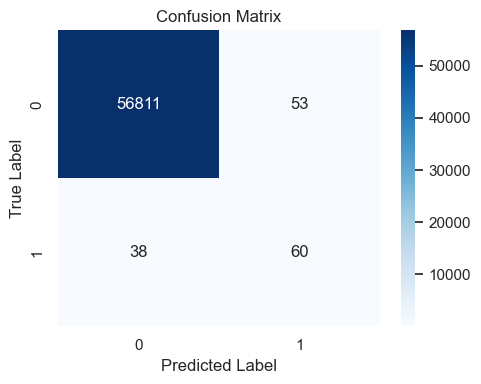

In [5]:
# Device Setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training data with normal behavior only
X_train_normal = X_train[y_train == 0]

# Tensor transformation
X_train_tensor = torch.tensor(X_train_normal.values, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train_tensor), batch_size=256, shuffle=True)

# Autoencoder Architecture
class Autoencoder(nn.Module):
    def __init__(self, input_dim):
        super(Autoencoder, self).__init__()
        # Encoder (compresses information to lower dimensions, latent space)
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU()
        )
        # Decoder (Reconstructs original shape)
        self.decoder = nn.Sequential(
            nn.Linear(8, 16),
            nn.ReLU(),
            nn.Linear(16, input_dim)
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

input_dim = X_train.shape[1]
model = Autoencoder(input_dim).to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Autoencoder Training with normal data only
epochs = 20
model.train()
for epoch in range(epochs):
    running_loss = 0.0
    
    for batch in train_loader:
        inputs = batch[0].to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, inputs)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    
    if (epoch + 1) % 2 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss/len(train_loader):.6f}")

# Model evaluation (including normal and fraud)
model.eval()
with torch.no_grad():
    predictions = model(X_test_tensor.to(device))
    # Sample Mean Standard Error
    mse = torch.mean((X_test_tensor.to(device) - predictions) ** 2, dim=1).cpu().numpy()
    

# Optimal threshold selection based on F1 Score
precisions, recalls, thresholds = precision_recall_curve(y_test, mse)
auprc_ae = auc(recalls, precisions)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

y_pred_autoencoder = (mse > best_threshold).astype(int)

print(f"\n{b_start}=== Autoencoder Evaluation Report ==={b_end}")
print(f"Best MSE Threshold: {best_threshold:.4f}")
print(f"ROC-AUC Score: {roc_auc_score(y_test, mse):.4f}")
print(f"AUPRC Autoencoder: {auprc_ae:.4f}")
print(classification_report(y_test, y_pred_autoencoder))
plot_confusion_matrix(y_test, y_pred_autoencoder)

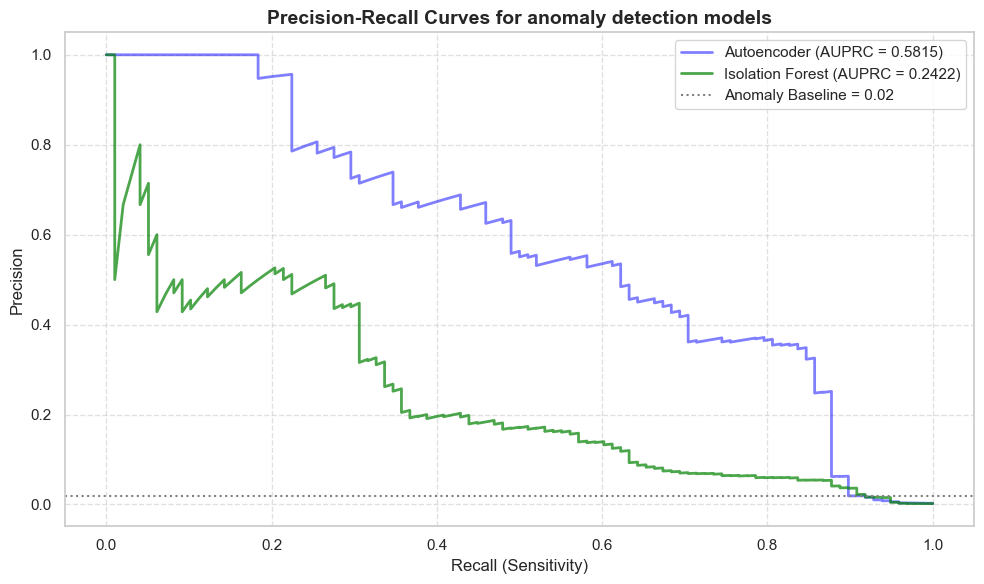

In [7]:
# Precision vs Recall Curve
# Autoencoder Curve
plt.figure(figsize=(10,6))
plt.plot(recalls, precisions, color='blue', linewidth=2, alpha=0.5, 
         label=f'Autoencoder (AUPRC = {auprc_ae:.4f})')

# Isolation Forest Curve
plt.plot(recall_if, precision_if, color='green', linewidth=2, alpha=0.70,
         label=f'Isolation Forest (AUPRC = {auprc_if:.4f})')

# Anomalies Baseline
plt.axhline(y=0.02, color='gray', linestyle=':', linewidth=1.5, 
            label='Anomaly Baseline = 0.02')

# Graph labeling
plt.title('Precision-Recall Curves for anomaly detection models', fontsize=14, fontweight='bold')
plt.xlabel('Recall (Sensitivity)', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right', fontsize=11)

# 7. Mostrar el gráfico
plt.tight_layout()
plt.show()

=== XGBoost Classification ===
Total number of data points: 227845

=== Classification Report ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.35      0.87      0.50        98

    accuracy                           1.00     56962
   macro avg       0.68      0.93      0.75     56962
weighted avg       1.00      1.00      1.00     56962

=== Confusion Matrix ===


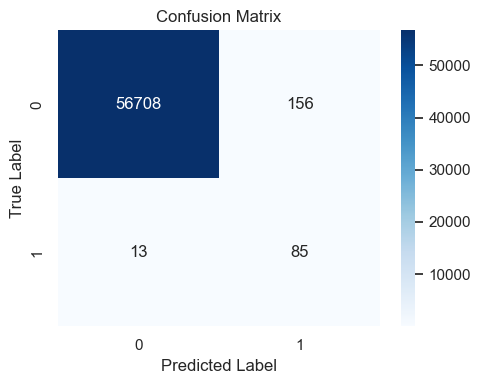

In [8]:
# SMOTE class rebalance
smote = SMOTE(random_state=101)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

# XGBoost model training
xgb_model = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=5,
    learning_rate=0.1,
    eval_metric="logloss",
    random_state=101
)

xgb_model.fit(X_train_res, y_train_res)

# Predictions
predictions_xgb = xgb_model.predict(X_test)
predict_prob = xgb_model.predict_proba(X_test)[:, 1]

# Print the number of predicted anomalies
print(f'{b_start}=== XGBoost Classification ==={b_end}')
print(f'Total number of data points: {len(X_train)}')
print()
print(f'{b_start}=== Classification Report ==={b_end}')
print(classification_report(y_test, predictions_xgb))
print(f'{b_start}=== Confusion Matrix ==={b_end}')
plot_confusion_matrix(y_test, predictions_xgb)
print()

In [13]:
# Anomaly score calculation using Autoencoder values
X_tensor = torch.tensor(X.values, dtype=torch.float32)
model.eval()
with torch.no_grad():
    reconstructed = model(X_tensor)

reconstruction_error = torch.mean((X_tensor - reconstructed) ** 2, dim=1)
scores_ae = reconstruction_error.cpu().numpy()
scaler = MinMaxScaler()

# Assign anomaly scores and predicted probabilities
data["ae_anomaly_score"] = scaler.fit_transform(scores_ae.reshape(-1, 1))
data["if_anomaly_score"] = iso_forest.score_samples(X)
data["xgb_predicted_fraud_prob"] = xgb_model.predict_proba(X)[:, 1]

# Enriched Dataframe Export
file_name = 'anomaly_classification_enriched.csv'
data.to_csv(fr'{PROCESSED_DATA_DIR}\{file_name}', index=False, sep=';')
print(f'Dataframe {file_name} exported to folder {PROCESSED_DATA_DIR}')

Dataframe anomaly_classification_enriched.csv exported to folder C:\Users\ASUS\OneDrive\Desktop\Proyectos\Consumer-Complaints-Fraud-Correlation-Analysis\notebooks\..\data\processed_data


In [18]:
# Anomaly Enriched Dataset Load
print('Dataframe Loading...')
anomaly_enriched = pd.read_csv(fr'{PROCESSED_DATA_DIR}\anomaly_classification_enriched.csv', low_memory=False, delimiter=';')
anomaly_enriched["if_anomaly_score"] = anomaly_enriched["if_anomaly_score"].abs()
print('Dataframe Correctly Loaded')

Dataframe Loading...
Dataframe Correctly Loaded


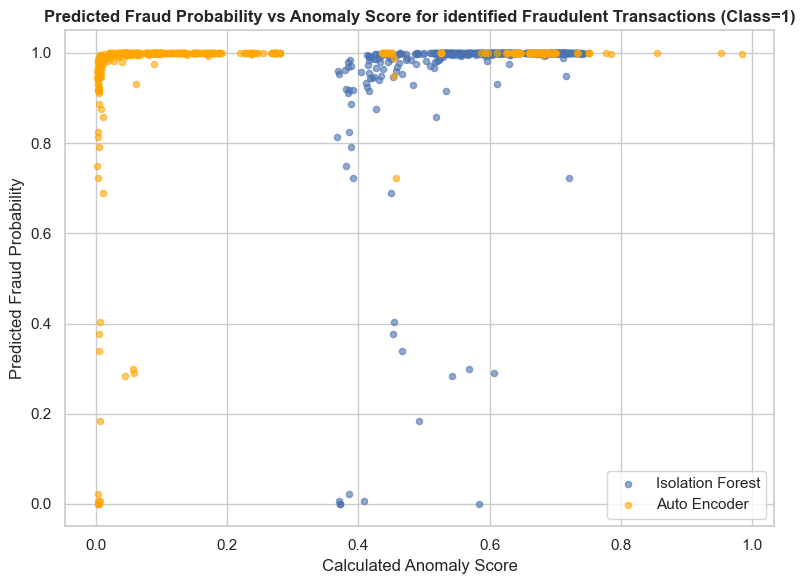

In [36]:
# Model labeling check
fig, ax = plt.subplots(figsize=(8, 6))

anomaly_enriched.query('Class == 1').plot(
    x='if_anomaly_score',
    y='xgb_predicted_fraud_prob',
    kind='scatter',
    label='Isolation Forest',
    ax=ax,
    alpha=0.6
)

anomaly_enriched.query('Class == 1').plot(
    x='ae_anomaly_score',
    y='xgb_predicted_fraud_prob',
    kind='scatter',
    label='Auto Encoder',
    ax=ax,
    alpha=0.6,
    c='orange'
)

ax.set_xlabel('Calculated Anomaly Score')
ax.set_ylabel('Predicted Fraud Probability')
ax.set_title('Predicted Fraud Probability vs Anomaly Score for identified Fraudulent Transactions (Class=1)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()